# Exploring scRNA-seq data using scanpy PBMC public dataset

In [28]:
import scanpy as sc 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
print("Environment ready")

Environment ready


In [29]:
adata = sc.datasets.pbmc3k()
adata

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'

In [30]:
# look at the cell info
adata.obs.head()

""
index
AAACATACAACCAC-1
AAACATTGAGCTAC-1
AAACATTGATCAGC-1
AAACCGTGCTTCCG-1
AAACCGTGTATGCG-1


In [31]:
# look at the gene info
adata.var.head()

,gene_ids
index,
MIR1302-10,ENSG00000243485
FAM138A,ENSG00000237613
OR4F5,ENSG00000186092
RP11-34P13.7,ENSG00000238009
RP11-34P13.8,ENSG00000239945


In [32]:
type(adata)

anndata._core.anndata.AnnData

In [33]:
adata.X[:5,:5].toarray()

array([[0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.]], dtype=float32)

In [34]:
sc.pp.calculate_qc_metrics(adata, inplace=True)

In [35]:
adata.obs.head()

,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes
index,,,,,,,,
AAACATACAACCAC-1,781,6.661855,2421.0,7.792349,47.748864,63.279637,74.969021,88.393226
AAACATTGAGCTAC-1,1352,7.210080,4903.0,8.497807,45.502753,61.023863,71.813176,82.622884
AAACATTGATCAGC-1,1131,7.031741,3149.0,8.055158,41.314703,53.794856,65.449349,79.961893
AAACCGTGCTTCCG-1,960,6.867974,2639.0,7.878534,39.029936,52.898825,66.691929,82.569155
AAACCGTGTATGCG-1,522,6.259581,981.0,6.889591,44.852192,55.657492,67.176351,97.757390


## QC
Plotting violin plots of n genes by counts, which is how many unique genes are expressed in a cell, and total counts, which is total transcripts per cell. 

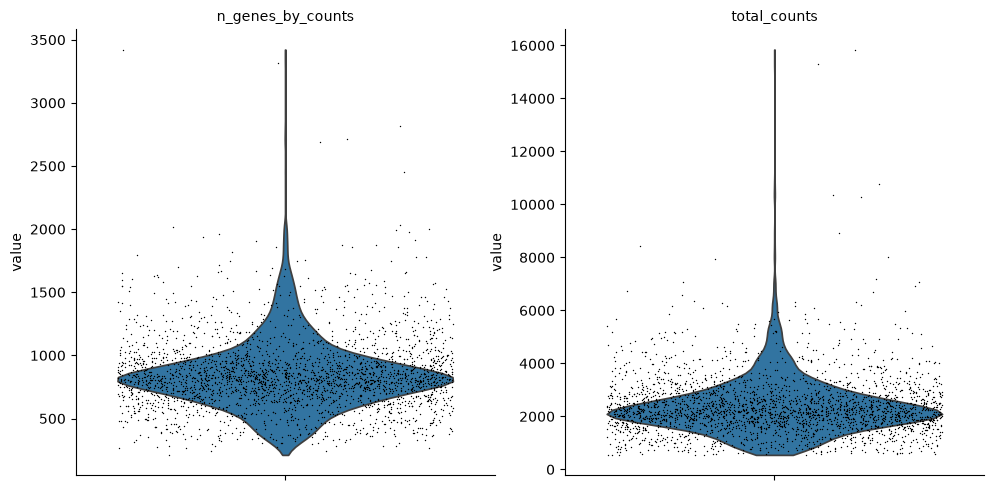

In [36]:
# plotting the number of genes detected in each cell shows us that most cells express about 900 genes and few express a lot more 
# it also shows us that most cells have about 2000 transcripts and few have more than that
# this plots the data from 2 cols in adata.obs
sc.pl.violin(
    adata, 
    ["n_genes_by_counts", "total_counts"], 
    jitter=0.4, 
    multi_panel=True
)

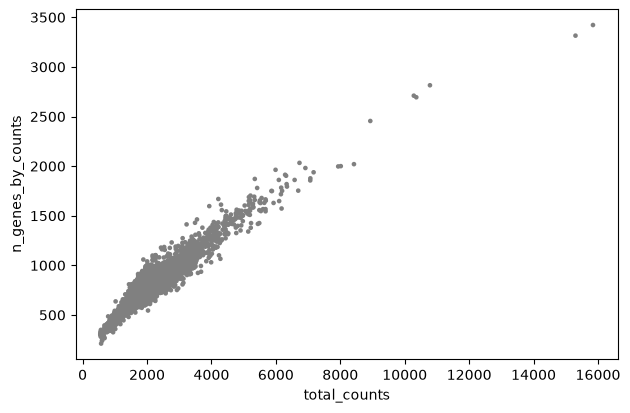

In [37]:
sc.pl.scatter(
    adata,
    x="total_counts",
    y="n_genes_by_counts"
)
# the more rna molecules there are the more genes they express, but they're clustered in a certain range

Total counts and n genes by counts have a linear relationship, which makes sense. If there are a lot of transcripts, they liekly come from many more genes. 

In [38]:
# since obs is a pd df, you use 2 brackets to select 2 cols 
# describe takes those 2 cols and tells you metrics for all cells
# count tells you the number of cells, mean tells how many genes on average each cell expresses, and how many rnas seen in each cell on average 

adata.obs[["n_genes_by_counts", "total_counts"]].describe()


,n_genes_by_counts,total_counts
count,2700.000000,2700.000000
mean,846.994074,2366.900391
std,282.104964,1094.262085
min,212.000000,548.000000
25%,690.000000,1757.750000
50%,817.000000,2197.000000
75%,953.250000,2763.000000
max,3422.000000,15844.000000


In [39]:
# creates a new col in var called mt that takes all the mt genes and their data
adata.var["mt"] = adata.var_names.str.startswith("MT")

# calculates qc metrics on the mt genes 
sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt"],  
    inplace=True
)

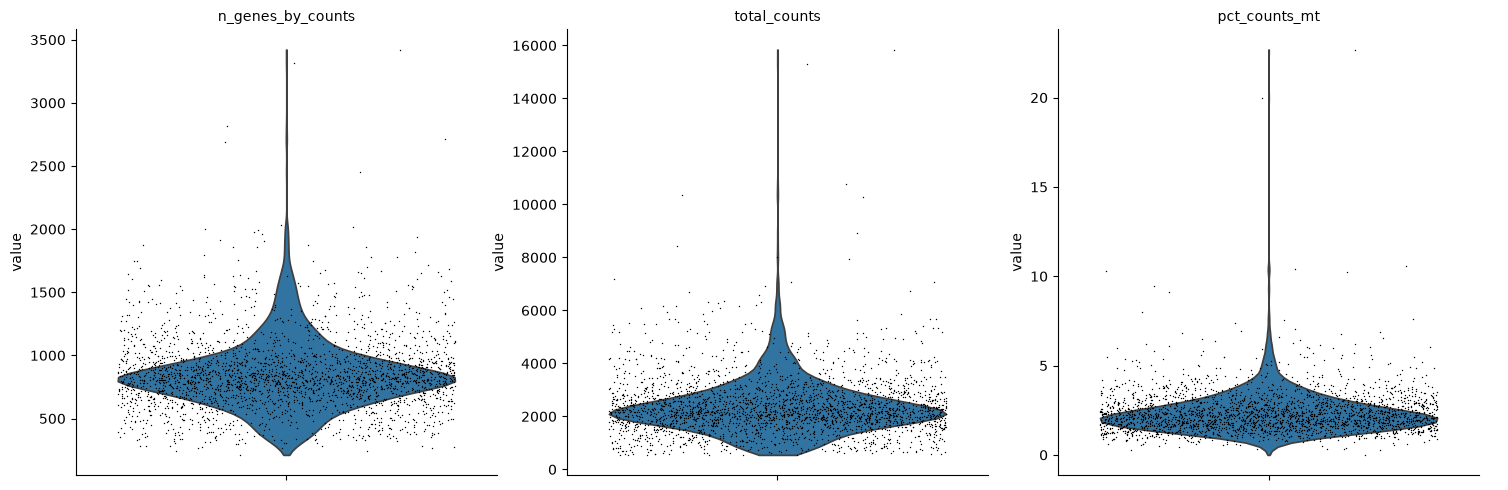

In [40]:
# scanpy searches for the df .obs only for .violin
sc.pl.violin(
    adata, 
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"], 
    jitter=0.4, 
    multi_panel=True
)
# i notice that most cells have 900 genes in them
# most cells have 2000 rna molecules in them 
# most cells have 3% mt genes making up all genes 

In [41]:
# gives stats for pct counts of mt rna across all cells 
adata.obs["pct_counts_mt"].describe()
# avg 2.3% mtrna, std is 1.1, some have no mtrna, 75% is 2.7 and the max is really high at 22 

count    2700.000000
mean        2.356714
std         1.175540
min         0.000000
25%         1.655864
50%         2.168459
75%         2.797307
max        22.689075
Name: pct_counts_mt, dtype: float64

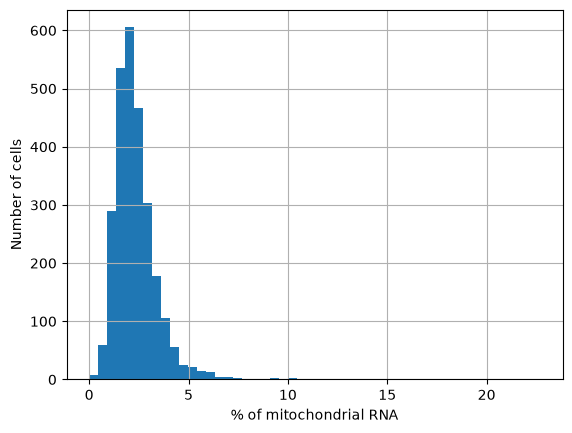

In [42]:
adata.obs["pct_counts_mt"].hist(bins=50)
plt.xlabel("% of mitochondrial RNA")
plt.ylabel("Number of cells")
plt.show()

Mt RNA content is low, most below 5%.
Now, I'm dropping cells that express from too little genes or too many genes (2 cells could've been sequenced as one). These thresholds are standard from the scanpy tutorial. 

In [43]:
# save original count of cells 
n_before = adata.n_obs

# adjust what we care to see in adata
# keep cells that express at least 300 and no more than 2500 different genes and 
adata = adata[adata.obs.n_genes_by_counts > 300, :]
adata = adata[adata.obs.n_genes_by_counts < 2500, :]

# also dropping cells that have too much rna (indicates low quality)
adata = adata[adata.obs.pct_counts_mt < 5, :]

# count after filtering
n_after = adata.n_obs

print(f"{n_before} cells before, {n_after} cells after")

2700 cells before, 2616 cells after


In [44]:
sc.pp.normalize_total(adata, target_sum=10000)
# target sum means the expression data is normalized so that if you add up all counts of rna molecules for each cell they'd be approx 10000

adata.obs["total_counts"].head()
# normalizing the data doesn't change total counts because its exists in the obs df not the X df

/Users/yukamurakami/miniconda3/envs/element-prep/lib/python3.11/site-packages/scanpy/preprocessing/_normalization.py:269: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


index
AAACATACAACCAC-1    2421.0
AAACATTGAGCTAC-1    4903.0
AAACATTGATCAGC-1    3149.0
AAACCGTGCTTCCG-1    2639.0
AAACCGTGTATGCG-1     981.0
Name: total_counts, dtype: float32

In [45]:
# lets see the X df to see the normalization
adata.X.sum(axis=1)
# adding up expression values across cols totals to 10000 bc each cell expresses approx 10000 molecules

matrix([[10000.   ],
        [10000.   ],
        [10000.   ],
        ...,
        [10000.001],
        [10000.   ],
        [10000.   ]], shape=(2616, 1), dtype=float32)

In [46]:
# make it a np arr and flatten it to a vector and show first 10
# all values are close to 10000 bc each cell expresses about the same rna 
np.array(adata.X.sum(axis=1)).flatten()[:10]

array([10000.   , 10000.   , 10000.   ,  9999.998,  9999.999, 10000.   ,
        9999.999, 10000.   , 10000.001, 10000.   ], dtype=float32)

In [47]:
# log transform adata to adjust large skewed values
# this makes large values smaller and small values bigger 
sc.pp.log1p(adata)

In [48]:
bef = adata.n_vars
sc.pp.highly_variable_genes(adata)
print(bef, adata.n_vars)
# adds new col called highly_variable which tells you if the gene varies across cell types or not
adata.var.head()


32738 32738


,gene_ids,n_cells_by_counts,mean_counts,log1p_mean_counts,pct_dropout_by_counts,total_counts,log1p_total_counts,mt,highly_variable,means,dispersions,dispersions_norm
index,,,,,,,,,,,,
MIR1302-10,ENSG00000243485,0,0.0,0.0,100.0,0.0,0.0,False,False,1.000000e-12,NaN,NaN
FAM138A,ENSG00000237613,0,0.0,0.0,100.0,0.0,0.0,False,False,1.000000e-12,NaN,NaN
OR4F5,ENSG00000186092,0,0.0,0.0,100.0,0.0,0.0,False,False,1.000000e-12,NaN,NaN
RP11-34P13.7,ENSG00000238009,0,0.0,0.0,100.0,0.0,0.0,False,False,1.000000e-12,NaN,NaN
RP11-34P13.8,ENSG00000239945,0,0.0,0.0,100.0,0.0,0.0,False,False,1.000000e-12,NaN,NaN


## Highly variable genes to find meaningful genes

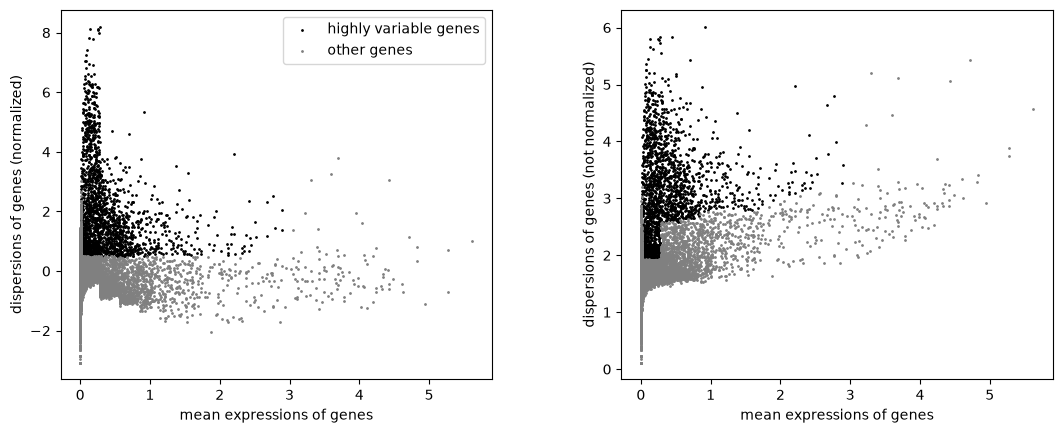

In [49]:
sc.pl.highly_variable_genes(adata)
# most genes are highly variable, many express around same range 
# y axis, the higher, the more variable the expression between T and B cells are, 
# the genes near the top might be best?
# the genes to the right are expressed most but we care more about how variable the genes are


High dispersion is a signal that a gene is likely to be useful for distinguishing cells from each other. Genes that have lower expression means have high dispersions. This may be due to hvg being expressed a lot in some cells but very little/none in others. The genes that have high mean expression may be expressing pretty similarly across different cells, making them not as informative. Therefore, this scatter plot shows what is expected biologically. 

In [50]:
# filter with just the highly variable genes
adata = adata[:, adata.var["highly_variable"]]
print(f"only {adata.n_vars} genes remain, there were {bef} before")


only 1987 genes remain, there were 32738 before


## PCA
Running pca on 1987 genes, the default number of pcs is 50. We need to find principle components before we make a neighborhood graph. And we need a neighborhood graph to cluster. 

In [51]:
# we have 1987 features now, which is way less than 32k but we can still reduce it using pca
# pca will help us find pcs that capture the important insights 
sc.tl.pca(adata)
# view the np arr called X_pca stored in obsm, which is a container like a dict using [] for access
adata.obsm["X_pca"].shape
# there are 50 pcs and 2616 cells 


/Users/yukamurakami/miniconda3/envs/element-prep/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:384: ImplicitModificationWarning: Setting element `.obsm['X_pca']` of view, initializing view as actual.
  adata.obsm[key_obsm] = x_pca


(2616, 50)

In [52]:
# lets look at first 5 pcs
adata.obsm["X_pca"][:, 5]
# with these 50 pcs we have a cleaner feature space 

array([-1.2348514 ,  0.21611352,  1.0278559 , ...,  0.21296284,
        0.22195229, -0.8269905 ], shape=(2616,), dtype=float32)

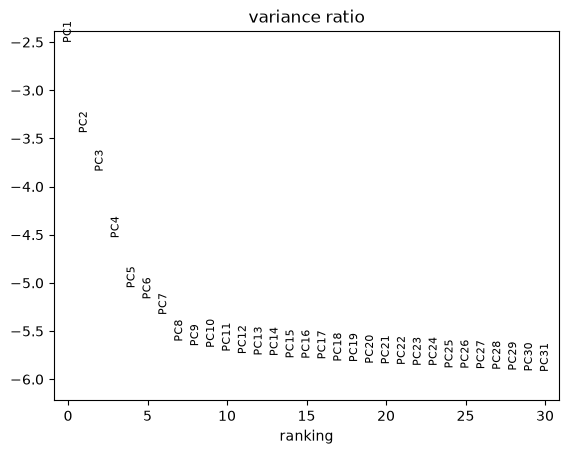

In [53]:
# lets use scree plot to visualize the pcs 
sc.pl.pca_variance_ratio(adata, log=True)

The first 7 pcs seem to capture variance the best. We'll include the first 10 to be safe. 

In [54]:
adata.write("data/processed_pbmc.h5ad")